In [18]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
from glob import glob
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

##Import any other packages you may need here
from itertools import chain
from skimage.io import imread
from random import sample
sns.set_style('whitegrid')

EDA is open-ended, and it is up to you to decide how to look at different ways to slice and dice your data. A good starting point is to look at the requirements for the FDA documentation in the final part of this project to guide (some) of the analyses you do. 

This EDA should also help to inform you of how pneumonia looks in the wild. E.g. what other types of diseases it's commonly found with, how often it is found, what ages it affects, etc. 

Note that this NIH dataset was not specifically acquired for pneumonia. So, while this is a representation of 'pneumonia in the wild,' the prevalence of pneumonia may be different if you were to take only chest x-rays that were acquired in an ER setting with suspicion of pneumonia. 

Perform the following EDA:
* The patient demographic data such as gender, age, patient position,etc. (as it is available)
* The x-ray views taken (i.e. view position)
* The number of cases including: 
    * number of pneumonia cases,
    * number of non-pneumonia cases
* The distribution of other diseases that are comorbid with pneumonia
* Number of disease per patient 
* Pixel-level assessments of the imaging data for healthy & disease states of interest (e.g. histograms of intensity values) and compare distributions across diseases.

Note: use full NIH data to perform the first a few EDA items and use `sample_labels.csv` for the pixel-level assassements. 

Also, **describe your findings and how will you set up the model training based on the findings.**

In [19]:
## Below is some helper code to read data for you.
## Load NIH data
all_xray_df = pd.read_csv('/data/Data_Entry_2017.csv')
all_xray_df.sample(3)

## Load 'sample_labels.csv' data for pixel level assessments
sample_df = pd.read_csv('sample_labels.csv')
sample_df.sample(3)

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImageWidth,OriginalImageHeight,OriginalImagePixelSpacing_x,OriginalImagePixelSpacing_y
4619,00023097_001.png,Atelectasis|Effusion,1,23097,037Y,M,PA,2992,2991,0.143,0.143
3981,00019663_004.png,Atelectasis|Effusion,4,19663,075Y,F,PA,2446,2372,0.143,0.143
1489,00007735_041.png,Effusion,41,7735,032Y,M,AP,2500,2048,0.168,0.168


In [20]:
## EDA
# Todo 

print('Number of images :', all_xray_df.shape[0])
print('Number of unique patients :', all_xray_df['Patient ID'].nunique())
print('Columns :', list(all_xray_df.columns))
all_xray_df.describe()

Number of images : 112120
Number of unique patients : 30805
Columns : ['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]', 'Unnamed: 11']


,Follow-up #,Patient ID,Patient Age,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
count,112120.000000,112120.000000,112120.000000,112120.000000,112120.000000,112120.000000,112120.000000,0.0
mean,8.573751,14346.381743,46.901463,2646.078844,2486.438842,0.155649,0.155649,NaN
std,15.406320,8403.876972,16.839923,341.246429,401.268227,0.016174,0.016174,NaN
min,0.000000,1.000000,1.000000,1143.000000,966.000000,0.115000,0.115000,NaN
25%,0.000000,7310.750000,35.000000,2500.000000,2048.000000,0.143000,0.143000,NaN
50%,3.000000,13993.000000,49.000000,2518.000000,2544.000000,0.143000,0.143000,NaN
75%,10.000000,20673.000000,59.000000,2992.000000,2991.000000,0.168000,0.168000,NaN
max,183.000000,30805.000000,414.000000,3827.000000,4715.000000,0.198800,0.198800,NaN


In [21]:
all_labels = np.unique(list(chain(*all_xray_df['Finding Labels'].map(lambda x: x.split('|')).tolist())))
all_labels = [x for x in all_labels if len(x) > 0]
print('All labels ({}): {}'.format(len(all_labels), all_labels))

for c_label in all_labels:
    all_xray_df[c_label] = all_xray_df['Finding Labels'].map(lambda finding: 1.0 if c_label in finding.split('|') else 0.0)

disease_labels = [l for l in all_labels if l != 'No Finding']
all_xray_df.sample(3)

All labels (15): ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Effusion', 'Emphysema', 'Fibrosis', 'Hernia', 'Infiltration', 'Mass', 'No Finding', 'Nodule', 'Pleural_Thickening', 'Pneumonia', 'Pneumothorax']


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,...,Emphysema,Fibrosis,Hernia,Infiltration,Mass,No Finding,Nodule,Pleural_Thickening,Pneumonia,Pneumothorax
109873,00029886_001.png,No Finding,1,29886,32,F,AP,3056,2544,0.139,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
15862,00004191_000.png,No Finding,0,4191,31,F,PA,2870,2991,0.143,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
73747,00018129_000.png,No Finding,0,18129,49,F,PA,2202,2488,0.143,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


Age range in raw data: 1 - 414
Records with age > 100 (data-entry errors): 16


,Image Index,Patient Age,Finding Labels
20852,00005567_000.png,412,Effusion|Pneumonia
46965,00011973_002.png,414,Edema
48284,00012238_010.png,148,No Finding
55742,00013950_000.png,148,No Finding
58650,00014520_026.png,150,Infiltration|Mass
62929,00015558_000.png,149,No Finding
74884,00018366_044.png,152,Pneumothorax
78795,00019346_000.png,151,Infiltration
84810,00020900_002.png,411,No Finding
85404,00021047_002.png,412,Mass|Pleural_Thickening


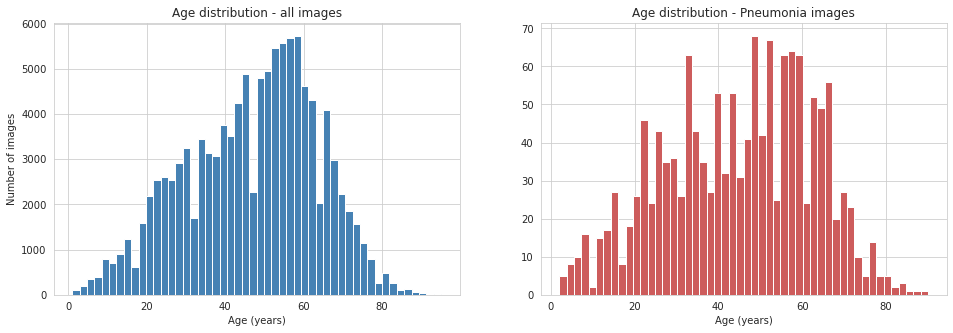

All images - age mean 46.9, median 49.0, std 16.6
Pneumonia  - age mean 44.7, median 46.0, std 17.6


In [22]:
# Age: check for invalid values first
print('Age range in raw data: {} - {}'.format(all_xray_df['Patient Age'].min(), all_xray_df['Patient Age'].max()))
print('Records with age > 100 (data-entry errors):', (all_xray_df['Patient Age'] > 100).sum())
display(all_xray_df.loc[all_xray_df['Patient Age'] > 100, ['Image Index', 'Patient Age', 'Finding Labels']])

# Keep only plausible ages for the demographic plots
xray_df = all_xray_df[all_xray_df['Patient Age'] <= 100].copy()

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
axs[0].hist(xray_df['Patient Age'], bins=50, color='steelblue')
axs[0].set_title('Age distribution - all images')
axs[0].set_xlabel('Age (years)'); axs[0].set_ylabel('Number of images')

pneu = xray_df[xray_df['Pneumonia'] == 1]
axs[1].hist(pneu['Patient Age'], bins=50, color='indianred')
axs[1].set_title('Age distribution - Pneumonia images')
axs[1].set_xlabel('Age (years)')
plt.show()

print('All images - age mean {:.1f}, median {:.1f}, std {:.1f}'.format(
    xray_df['Patient Age'].mean(), xray_df['Patient Age'].median(), xray_df['Patient Age'].std()))
print('Pneumonia  - age mean {:.1f}, median {:.1f}, std {:.1f}'.format(
    pneu['Patient Age'].mean(), pneu['Patient Age'].median(), pneu['Patient Age'].std()))

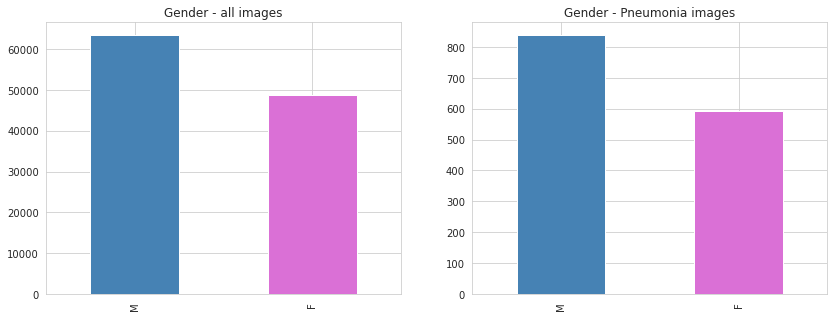

All images:
 M    0.565
F    0.435
Name: Patient Gender, dtype: float64
Pneumonia:
 M    0.585
F    0.415
Name: Patient Gender, dtype: float64
Unique patients by gender:
 M    16629
F    14173
Name: Patient Gender, dtype: int64


In [23]:
# Gender
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
xray_df['Patient Gender'].value_counts().plot(kind='bar', ax=axs[0], color=['steelblue', 'orchid'])
axs[0].set_title('Gender - all images')
pneu['Patient Gender'].value_counts().plot(kind='bar', ax=axs[1], color=['steelblue', 'orchid'])
axs[1].set_title('Gender - Pneumonia images')
plt.show()

print('All images:\n', xray_df['Patient Gender'].value_counts(normalize=True).round(3))
print('Pneumonia:\n', pneu['Patient Gender'].value_counts(normalize=True).round(3))

# Gender at the patient level (one row per patient)
print('Unique patients by gender:\n', xray_df.drop_duplicates('Patient ID')['Patient Gender'].value_counts())

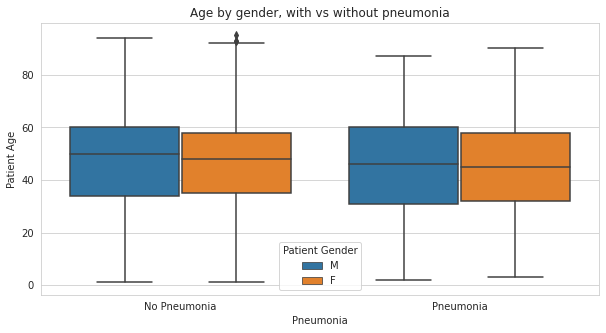

In [24]:
# Age by gender for pneumonia vs non-pneumonia
plt.figure(figsize=(10, 5))
sns.boxplot(x='Pneumonia', y='Patient Age', hue='Patient Gender', data=xray_df)
plt.xticks([0, 1], ['No Pneumonia', 'Pneumonia'])
plt.title('Age by gender, with vs without pneumonia')
plt.show()

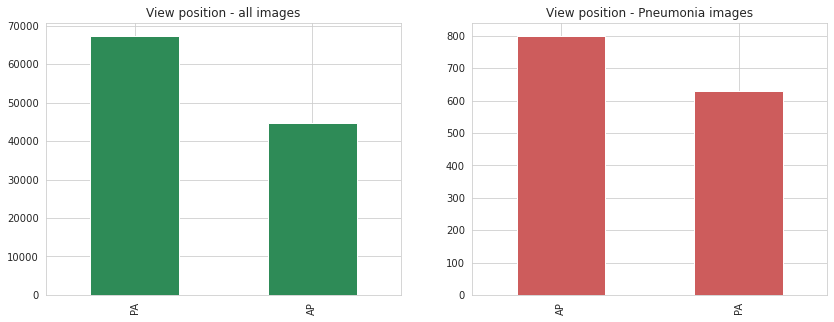

All images:
 PA    0.6
AP    0.4
Name: View Position, dtype: float64
Pneumonia:
 AP    0.559
PA    0.441
Name: View Position, dtype: float64


In [25]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
xray_df['View Position'].value_counts().plot(kind='bar', ax=axs[0], color='seagreen')
axs[0].set_title('View position - all images')
pneu['View Position'].value_counts().plot(kind='bar', ax=axs[1], color='indianred')
axs[1].set_title('View position - Pneumonia images')
plt.show()

print('All images:\n', xray_df['View Position'].value_counts(normalize=True).round(3))
print('Pneumonia:\n', pneu['View Position'].value_counts(normalize=True).round(3))

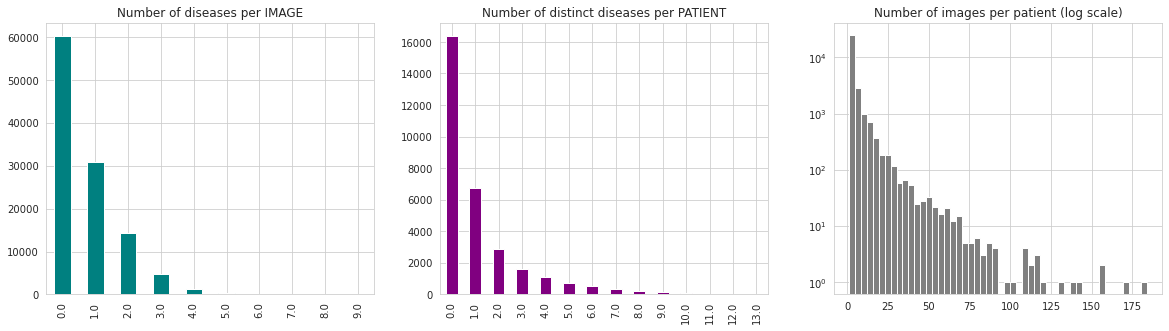

Mean diseases per image: 0.72
Mean distinct diseases per patient: 1.14
Mean images per patient: 3.64, max: 184
Pneumonia images - mean diseases per image: 2.33


In [26]:
all_xray_df['num_diseases'] = all_xray_df[disease_labels].sum(axis=1)

fig, axs = plt.subplots(1, 3, figsize=(20, 5))
all_xray_df['num_diseases'].value_counts().sort_index().plot(kind='bar', ax=axs[0], color='teal')
axs[0].set_title('Number of diseases per IMAGE')

# distinct diseases a patient ever had across all their images
per_patient = all_xray_df.groupby('Patient ID')[disease_labels].max().sum(axis=1)
per_patient.value_counts().sort_index().plot(kind='bar', ax=axs[1], color='purple')
axs[1].set_title('Number of distinct diseases per PATIENT')

imgs_per_patient = all_xray_df.groupby('Patient ID').size()
axs[2].hist(imgs_per_patient, bins=50, log=True, color='gray')
axs[2].set_title('Number of images per patient (log scale)')
plt.show()

print('Mean diseases per image: {:.2f}'.format(all_xray_df['num_diseases'].mean()))
print('Mean distinct diseases per patient: {:.2f}'.format(per_patient.mean()))
print('Mean images per patient: {:.2f}, max: {}'.format(imgs_per_patient.mean(), imgs_per_patient.max()))
print('Pneumonia images - mean diseases per image: {:.2f}'.format(
    all_xray_df.loc[all_xray_df['Pneumonia'] == 1, 'num_diseases'].mean()))

In [27]:
# map image names to full paths (the sample images live in the same image folders)
all_image_paths = {os.path.basename(x): x for x in glob(os.path.join('/data', 'images*', '*', '*.png'))}
sample_df['path'] = sample_df['Image Index'].map(all_image_paths.get)
sample_df = sample_df[sample_df['path'].notnull()].copy()
print('Sample images found:', sample_df.shape[0])

for c_label in all_labels:
    sample_df[c_label] = sample_df['Finding Labels'].map(lambda f: 1 if c_label in f.split('|') else 0)
print('Pneumonia images in sample:', sample_df['Pneumonia'].sum())

Sample images found: 5606
Pneumonia images in sample: 62


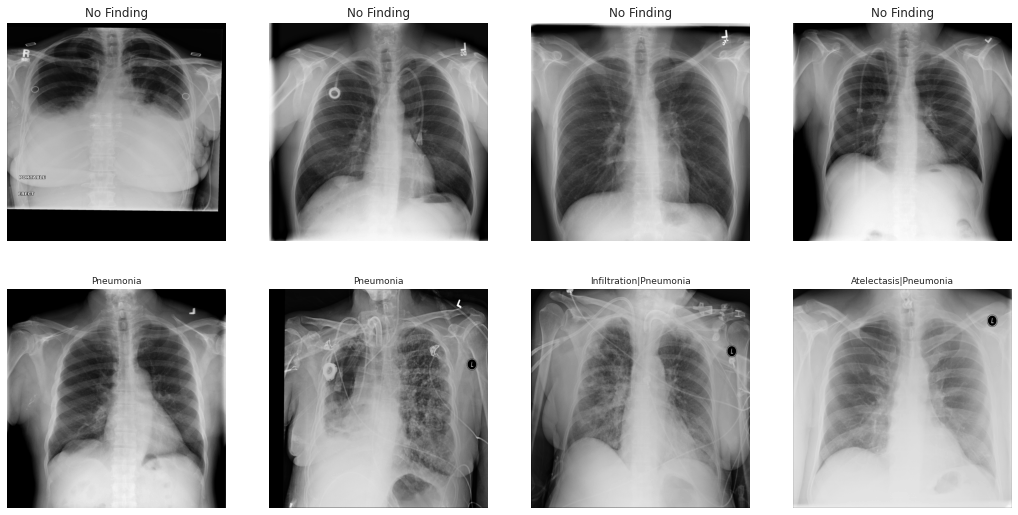

In [28]:
def load_gray(path):
    img = imread(path)
    if img.ndim == 3:          # a few NIH images are stored as RGB/RGBA
        img = img[:, :, 0]
    return img

# Show a few raw example images
fig, axs = plt.subplots(2, 4, figsize=(18, 9))
ex_no = sample_df[sample_df['No Finding'] == 1].sample(4, random_state=1)
ex_pn = sample_df[sample_df['Pneumonia'] == 1].sample(4, random_state=1)
for ax, (_, r) in zip(axs[0], ex_no.iterrows()):
    ax.imshow(load_gray(r['path']), cmap='gray'); ax.set_title('No Finding'); ax.axis('off')
for ax, (_, r) in zip(axs[1], ex_pn.iterrows()):
    ax.imshow(load_gray(r['path']), cmap='gray'); ax.set_title(r['Finding Labels'], fontsize=9); ax.axis('off')
plt.show()

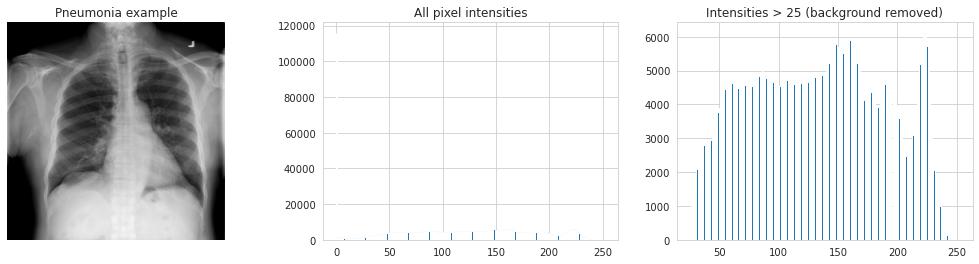

In [29]:
# Histogram of a single image, with and without the dark background
img = load_gray(ex_pn.iloc[0]['path'])
fig, axs = plt.subplots(1, 3, figsize=(18, 4))
axs[0].imshow(img, cmap='gray'); axs[0].axis('off'); axs[0].set_title('Pneumonia example')
axs[1].hist(img.ravel(), bins=256); axs[1].set_title('All pixel intensities')
axs[2].hist(img[img > 25].ravel(), bins=230); axs[2].set_title('Intensities > 25 (background removed)')
plt.show()

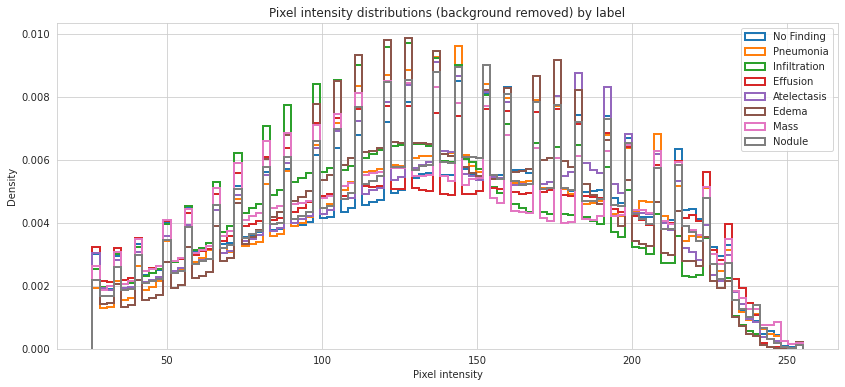

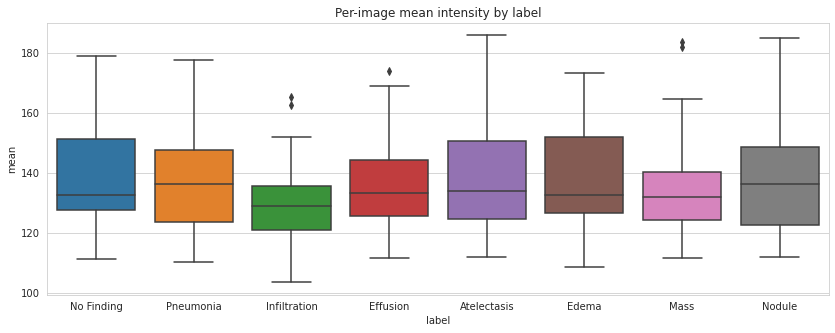

mean         std      
               mean   std  mean   std
label                                
Atelectasis   138.8  19.2  48.2  10.3
Edema         136.8  18.1  44.7   6.5
Effusion      136.9  15.4  52.1   8.2
Infiltration  130.0  15.2  47.3  10.5
Mass          135.4  17.8  51.1   8.9
No Finding    139.3  17.8  50.7   9.6
Nodule        138.0  19.1  47.9  10.2
Pneumonia     139.5  17.9  47.6   9.5

In [30]:
# Compare intensity distributions across diseases (pooled over many images per class)
compare_classes = ['No Finding', 'Pneumonia', 'Infiltration', 'Effusion', 'Atelectasis', 'Edema', 'Mass', 'Nodule']
N_PER_CLASS = 30
BG_THRESH = 25   # remove near-black background / borders

intensities = {}
stats = []
for c in compare_classes:
    subset = sample_df[sample_df[c] == 1]
    subset = subset.sample(min(N_PER_CLASS, len(subset)), random_state=0)
    pix = []
    for p in subset['path']:
        im = load_gray(p)
        pix.append(im[im > BG_THRESH].ravel())
        stats.append({'label': c, 'mean': im[im > BG_THRESH].mean(), 'std': im[im > BG_THRESH].std()})
    intensities[c] = np.concatenate(pix)

plt.figure(figsize=(14, 6))
for c in compare_classes:
    plt.hist(intensities[c], bins=100, density=True, histtype='step', linewidth=2, label=c)
plt.legend(); plt.xlabel('Pixel intensity'); plt.ylabel('Density')
plt.title('Pixel intensity distributions (background removed) by label')
plt.show()

stats_df = pd.DataFrame(stats)
plt.figure(figsize=(14, 5))
sns.boxplot(x='label', y='mean', data=stats_df)
plt.title('Per-image mean intensity by label')
plt.show()
stats_df.groupby('label')[['mean', 'std']].agg(['mean', 'std']).round(1)

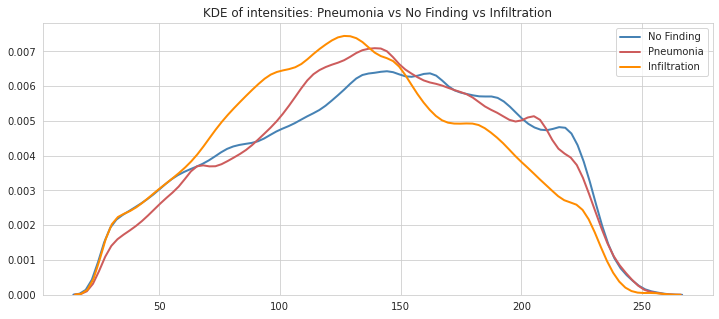

In [31]:
# Direct comparison: pneumonia vs no finding vs the most common pneumonia comorbidity (Infiltration)
plt.figure(figsize=(12, 5))
for c, col in zip(['No Finding', 'Pneumonia', 'Infiltration'], ['steelblue', 'indianred', 'darkorange']):
    sns.kdeplot(intensities[c][::50], label=c, color=col, linewidth=2)
plt.legend(); plt.title('KDE of intensities: Pneumonia vs No Finding vs Infiltration')
plt.show()

z## 8. Findings and how they shape model training

**Dataset size and prevalence**
- The NIH set has 112,120 frontal chest X-rays from 30,805 unique patients. Only about 1,431 images (≈1.3%) are labelled Pneumonia, so the data is highly imbalanced. More than half of the images are "No Finding".
- Labels were mined from radiology reports with NLP, so they're noisy (reported accuracy >90%). Pneumonia is especially hard to label from reports alone.

**Demographics**
- Men make up slightly more of the images (≈56% male, ≈44% female). The pneumonia subset has a similar split.
- Ages mostly fall between about 20 and 80 (mean ≈ 46–47 years). The pneumonia age distribution looks much like the overall one, with a small shift toward younger patients.
- A handful of records have ages above 100 (e.g. 148, 4xx). These are data-entry errors, and I removed them.

**View position**
- About 60% of images are PA and 40% are AP. AP makes up a larger share of the pneumonia images than of the whole dataset. That fits the fact that sicker, bedside patients are usually imaged AP with portable equipment.

**Comorbidity**
- Pneumonia usually appears with other findings: only a minority of pneumonia images carry "Pneumonia" alone. The most common co-findings are **Infiltration**, then **Edema**, **Effusion** and **Atelectasis**. These conditions look similar on X-ray, which makes pneumonia hard to separate from them.
- The average pneumonia image carries more labels than the average image overall.

**Diseases per patient**
- Most images have 0 or 1 disease label. Many patients have several follow-up images (up to ~180 for one patient). A random image-level split would therefore put the same patient in both train and validation.

**Pixel level**
- Each image has a large peak of near-black background/border pixels. I excluded these (intensity > 25) before comparing classes.
- Pneumonia intensity distributions overlap heavily with No Finding and especially with Infiltration, Edema and Effusion. Mean intensities differ only slightly between classes, so no simple intensity threshold separates pneumonia. The model has to learn spatial/texture patterns, which motivates a CNN.

**Decisions for model training**
1. **Binary target**: `pneumonia_class` = 1 if "Pneumonia" is in Finding Labels, otherwise 0. I kept comorbid cases as positives, because that's how pneumonia appears in practice.
2. **Split by patient**: all images from one patient go to the same split, which prevents data leakage.
3. **Training set balanced 50/50** (all training pneumonia images plus an equal random sample of negatives), so the network doesn't learn to always predict "negative".
4. **Validation set with realistic prevalence (~20% pneumonia)**. That's closer to a clinical setting where pneumonia is suspected, so precision, recall and F1 give an honest estimate. I used AUC, precision-recall and F1 rather than accuracy.
5. **Keep both AP and PA views** and all ages 1–100 and both genders, since the device is meant for all of them. Remove records with age > 100.
6. **Intensity normalisation** with the training-set mean and std, since raw intensity alone isn't discriminative. Use light, anatomically plausible augmentation: horizontal flip, small rotations, shifts and zoom, but **no vertical flips**.
7. Because labels are noisy and pneumonia is hard even for radiologists, the goal is a good screening/triage aid. The threshold is chosen for F1, favouring recall.